In [2]:

# Install required libraries
!pip install -q tensorflow numpy pandas matplotlib seaborn scikit-learn

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


Libraries imported successfully!
TensorFlow version: 2.21.0


Q1 – Text Preprocessing and Sequence Representation

In [3]:

# =========================
# Q1: TEXT PREPROCESSING
# =========================

# Load IMDb dataset
vocab_size = 10000
max_length = 200

(X_train_full, y_train_full), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train_full))
print("Testing samples:", len(X_test))
print("Vocabulary size:", vocab_size)

# Get word index
word_index = imdb.get_word_index()

reverse_word_index = {
    index + 3: word for word, index in word_index.items()
}

reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"

# Function to convert numbers into text
def decode_review(sequence):
    return " ".join(
        reverse_word_index.get(i, "?") for i in sequence
    )

# Display five sample reviews
print("\nFIVE SAMPLE REVIEWS")

for i in range(5):
    print("\nReview:", decode_review(X_train_full[i])[:500])
    print("Sentiment:",
          "Positive" if y_train_full[i] == 1 else "Negative")

# Vocabulary information
print("\nVocabulary Information")
print("Total vocabulary:", len(word_index))
print("Maximum vocabulary:", vocab_size)
print("Maximum sequence length:", max_length)

# Padding and truncation
X_train_full = pad_sequences(
    X_train_full,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

# Display three original reviews and sequences
print("\nORIGINAL REVIEWS AND NUMERICAL SEQUENCES")

for i in range(3):
    print("\nOriginal Review:")
    print(decode_review(X_train_full[i])[:500])

    print("\nNumerical Sequence:")
    print(X_train_full[i][:50])

# Dataset dimensions
print("\nDataset Dimensions")
print("Training data:", X_train_full.shape)
print("Testing data:", X_test.shape)

# Split training data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("\nFinal Data Split")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nQ1 COMPLETED")


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training samples: 25000
Testing samples: 25000
Vocabulary size: 10000
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

FIVE SAMPLE REVIEWS

Review: <START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would re
Sentiment: Positive

Review: <START> big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is a

Q2 – Implement RNN-Based Model

Simple RNN Model


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 48s 136ms/step - accuracy: 0.5511 - loss: 0.6821 - val_accuracy: 0.5842 - val_loss: 0.6739
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 46s 146ms/step - accuracy: 0.6832 - loss: 0.6018 - val_accuracy: 0.6252 - val_loss: 0.6331
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 70s 108ms/step - accuracy: 0.8573 - loss: 0.3336 - val_accuracy: 0.6566 - val_loss: 0.7431


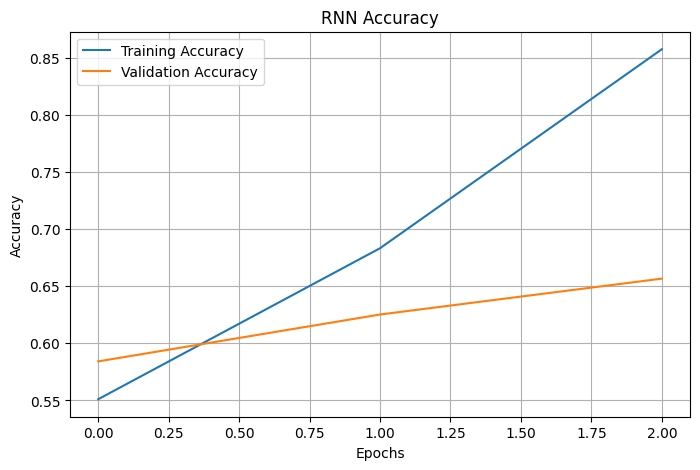

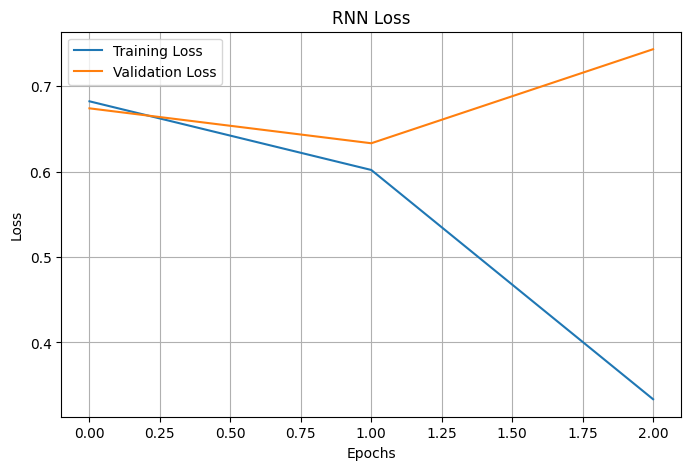


RNN Test Results
Accuracy: 0.62972
Precision: 0.6403045773124513
Recall: 0.592
F1 Score: 0.6152055534771584

Q2 COMPLETED


In [4]:

# =========================
# Q2: SIMPLE RNN MODEL
# =========================

# Create RNN model
rnn_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    SimpleRNN(64),
    Dense(1, activation="sigmoid")
])

# Compile model
rnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
print("Simple RNN Model")
rnn_model.summary()

# Early stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)

# Train model
history_rnn = rnn_model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

# Plot accuracy
plt.figure(figsize=(8,5))
plt.plot(history_rnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_rnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("RNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Plot loss
plt.figure(figsize=(8,5))
plt.plot(history_rnn.history["loss"], label="Training Loss")
plt.plot(history_rnn.history["val_loss"], label="Validation Loss")
plt.title("RNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# Evaluate model
rnn_pred = (
    rnn_model.predict(X_test, verbose=0) >= 0.5
).astype(int).flatten()

print("\nRNN Test Results")
print("Accuracy:", accuracy_score(y_test, rnn_pred))
print("Precision:", precision_score(y_test, rnn_pred))
print("Recall:", recall_score(y_test, rnn_pred))
print("F1 Score:", f1_score(y_test, rnn_pred))

print("\nQ2 COMPLETED")


Q3 – Implement and Compare RNN, LSTM and GRU

In [5]:

# =========================
# Q3: MODEL COMPARISON
# =========================

# Create Simple RNN
def create_rnn():
    model = Sequential([
        Embedding(vocab_size, 64, mask_zero=True),
        SimpleRNN(64),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


# Create LSTM
def create_lstm():
    model = Sequential([
        Embedding(vocab_size, 64, mask_zero=True),
        LSTM(64),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


# Create GRU
def create_gru():
    model = Sequential([
        Embedding(vocab_size, 64, mask_zero=True),
        GRU(64),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


# Build models
rnn_model = create_rnn()
lstm_model = create_lstm()
gru_model = create_gru()

# Display architectures
print("RNN Architecture")
rnn_model.summary()

print("\nLSTM Architecture")
lstm_model.summary()

print("\nGRU Architecture")
gru_model.summary()


# Train RNN
print("\nTraining RNN")
history_rnn = rnn_model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

# Train LSTM
print("\nTraining LSTM")
history_lstm = lstm_model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

# Train GRU
print("\nTraining GRU")
history_gru = gru_model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)


# Evaluate all models
models = {
    "Simple RNN": rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

results = []
predictions = {}

for name, model in models.items():

    pred = (
        model.predict(X_test, verbose=0) >= 0.5
    ).astype(int).flatten()

    predictions[name] = pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred)
    })


# Display comparison table
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))


# Select best model based on F1 score
best_name = results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_name]

print("\nBest Model:", best_name)


# Generate predictions for 10 test reviews
sample_predictions = (
    best_model.predict(X_test[:10], verbose=0) >= 0.5
).astype(int).flatten()

print("\nPREDICTIONS FOR 10 REVIEWS")

for i in range(10):

    actual = "Positive" if y_test[i] == 1 else "Negative"

    predicted = (
        "Positive" if sample_predictions[i] == 1 else "Negative"
    )

    print("\nReview:", decode_review(X_test[i])[:400])
    print("Actual Sentiment:", actual)
    print("Predicted Sentiment:", predicted)

print("\nQ3 COMPLETED")


RNN Architecture


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Training RNN
Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 43s 120ms/step - accuracy: 0.5983 - loss: 0.6600 - val_accuracy: 0.7656 - val_loss: 0.5082
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - accuracy: 0.7117 - loss: 0.5637 - val_accuracy: 0.6288 - val_loss: 0.6438

Training LSTM
Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 70s 215ms/step - accuracy: 0.7804 - loss: 0.4634 - val_accuracy: 0.8290 - val_loss: 0.3859
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 214ms/step - accuracy: 0.8857 - loss: 0.2946 - val_accuracy: 0.8452 - val_loss: 0.3803
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 67s 214ms/step - accuracy: 0.9161 - loss: 0.2275 - val_accuracy: 0.8418 - val_loss: 0.4128

Training GRU
Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 74s 223ms/step - accuracy: 0.7385 - loss: 0.5027 - val_accuracy: 0.7982 - val_loss: 0.4326
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 70s 223ms/step - accuracy: 0.8853 - loss: 0.2905 - val_accuracy: 0.8012 - val_loss: 0.4411

MODEL COMPARISON
     Model  Accuracy  Precisi

Q4 – Best Model Evaluation and Error Analysis

Best Performing Model: LSTM


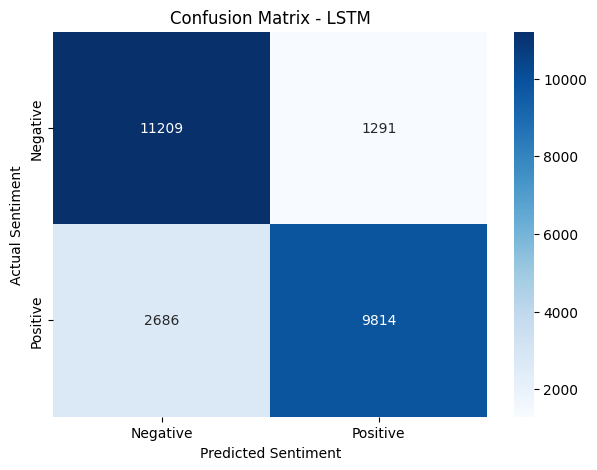


FINAL EVALUATION METRICS
Accuracy: 0.84092
Precision: 0.8837460603331833
Recall: 0.78512
F1 Score: 0.8315187460283838

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.81      0.90      0.85     12500
    Positive       0.88      0.79      0.83     12500

    accuracy                           0.84     25000
   macro avg       0.85      0.84      0.84     25000
weighted avg       0.85      0.84      0.84     25000


FIVE INCORRECTLY CLASSIFIED REVIEWS

Incorrect Review: 1
Review: <START> i generally love this type of movie however this time i found myself wanting to kick the screen since i can't do that i will just complain about it this was absolutely idiotic the things that happen with the dead kids are very cool but the alive people are absolute idiots i am a grown man pretty big and i can defend myself well however i would not do half the stuff the little girl does in this movie also the mother in this movie is reckless with her chi

In [6]:

# =========================
# Q4: ERROR ANALYSIS
# =========================

# Select best model from Q3
best_predictions = predictions[best_name]

print("Best Performing Model:", best_name)


# Confusion Matrix
cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()


# Evaluation Metrics
print("\nFINAL EVALUATION METRICS")

print("Accuracy:",
      accuracy_score(y_test, best_predictions))

print("Precision:",
      precision_score(y_test, best_predictions))

print("Recall:",
      recall_score(y_test, best_predictions))

print("F1 Score:",
      f1_score(y_test, best_predictions))


# Classification Report
print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    best_predictions,
    target_names=["Negative", "Positive"]
))


# Identify incorrectly classified reviews
incorrect_indices = np.where(
    best_predictions != y_test
)[0]

print("\nFIVE INCORRECTLY CLASSIFIED REVIEWS")

for count, index in enumerate(incorrect_indices[:5], start=1):

    actual = "Positive" if y_test[index] == 1 else "Negative"

    predicted = (
        "Positive" if best_predictions[index] == 1 else "Negative"
    )

    print("\nIncorrect Review:", count)
    print("Review:", decode_review(X_test[index])[:600])
    print("Actual Sentiment:", actual)
    print("Predicted Sentiment:", predicted)


# Error Analysis
print("\nERROR ANALYSIS")

print("""
1. Negation:
Words like not and never can change the meaning
of a sentence.

2. Long-distance dependencies:
The model may fail to understand relationships
between words that are far apart.

3. Sarcasm:
The actual meaning of a sentence may be different
from its literal meaning.

4. Ambiguous language:
Some words can have multiple meanings.

5. Mixed sentiment:
A review may contain both positive and negative opinions.

6. Unusual vocabulary:
The model may struggle with uncommon words.
""")


# Limitations
print("\nLIMITATIONS OF RNN MODELS")

print("""
1. Vanishing gradient problem.
2. Difficulty in learning long sequences.
3. Training can be time-consuming.
4. Difficulty understanding sarcasm.
5. Performance depends on training data.
""")


# Possible Improvements
print("\nPOSSIBLE IMPROVEMENTS")

print("""
1. Use a larger training dataset.
2. Increase embedding dimensions.
3. Tune model hyperparameters.
4. Use LSTM or GRU.
5. Use Bidirectional LSTM.
6. Use Transformer models such as BERT.
""")

print("\nNLP LAB ASSIGNMENT 7 COMPLETED SUCCESSFULLY!")
